# Figure 7 | Liquid water content and snow grain type

Powder Patch Meteorological Station (PPSA), WY 2025. The default is the PPSA met mixed forcing run with lapse-rate-corrected HRRR-AK fill
and soil enabled, as used in the main [Figure 4 notebook](figure4_publication.ipynb). Edit the settings cell to change the
model run, figure window, sampling, or scales.

Liquid water content is reported as volume percent in the PRO file. Vertical stripes identify melt–freeze crust (MFcr). Grain labels use the primary Swiss class, with a separate class for crust. FCxr indicates rounding faceted particles.

[SNOWPACK PRO format and grain codes](https://snowpack.slf.ch/doc-dev/html/snowpackio.html) · [NiViz grain-color and crust conventions](https://niviz.org/niviz/dist/doc/files/lib_graphs_gradient.js.html)

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'figures/notebooks/snowpack_profiles.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Start the notebook from the manuscript repository.')
sys.path.insert(0, str(root / 'figures/notebooks'))

from snowpack_profiles import plot_profiles, read_profiles, save_figure, water_year_window

In [ ]:
model_root = Path('/home/cassie/python/models/run_snowpack/sites')
site = 'ppsa'
simulation = 'met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil'
pro_path = model_root / site / 'output' / f'{simulation}.pro'
window = tuple(map(pd.Timestamp, ('2024-10-01', '2025-07-01')))
variables = ('liquid_water', 'grain_type')
sample_hours = 3
depth_max = 250
color_limits = {}  # Set per-variable limits to override the NiViz-style scales.
output_dir = root / 'figures/files'

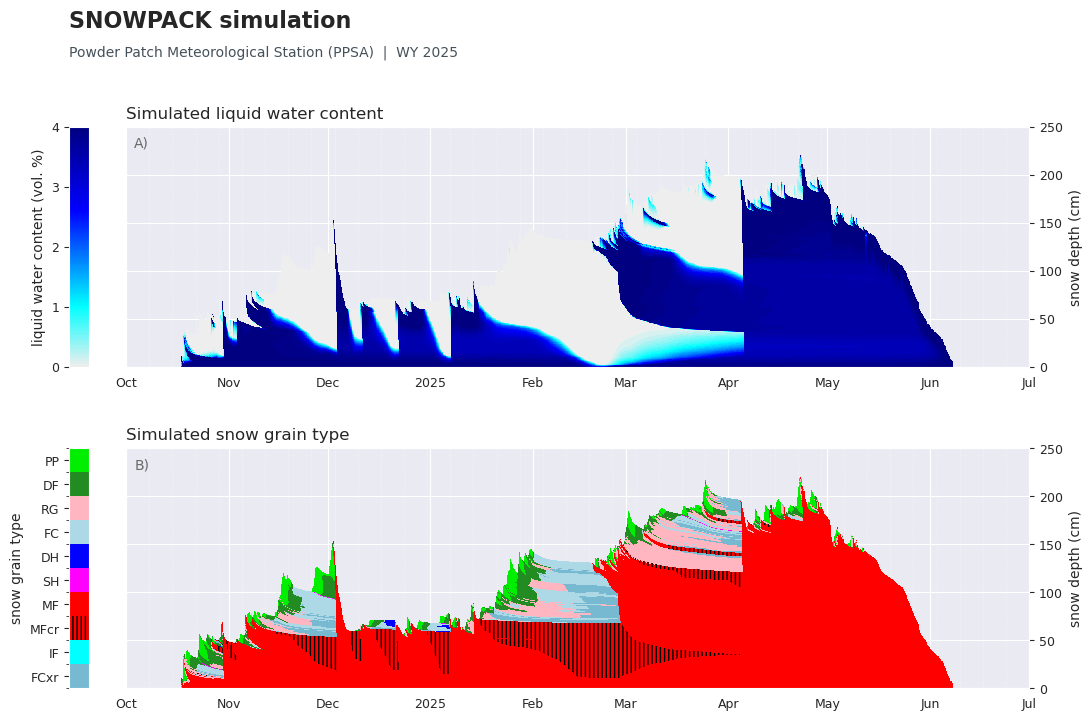

In [ ]:
profiles, cadence = read_profiles(pro_path, *window, variables, sample_hours=sample_hours)
fig = plot_profiles(profiles, cadence, variables, window,
                    heading='SNOWPACK simulation',
                    subtitle='Powder Patch Meteorological Station (PPSA)  |  WY 2025',
                    depth_max=depth_max, color_limits=color_limits)
save_figure(fig, output_dir, 'figure7_publication')
plt.show()